# k-Means

[Vorlesungsaufzeichnung k-Means (VL 16)](https://media.hhu.de/channel/video/data-science-vl-16-k-means-2025/4d7a11c94e56a89a8bd8acdeb03a7a0d/167)


## Einordnung: Klassifikation, Regression, Clustering

Ausgangspunkt jedes Verfahrens in diesem Teil des Buchs ist eine Tabelle: Zeilen sind Instanzen, Spalten sind Merkmale. Die erste Frage ist immer, ob eine Spalte als **Label** ausgezeichnet ist, also als die Größe, die wir vorhersagen wollen und die für die vorhandenen Zeilen bekannt ist (die *Ground Truth*).

* Gibt es ein Label, spricht man von **supervised learning**: Wir lernen den Zusammenhang zwischen den übrigen Spalten und dem Label, um es für neue Zeilen vorherzusagen. Ist das Label nominalskaliert (Spezies, Farbe, ja/nein), heißt die Aufgabe **Klassifikation**; ist es stetig (Preis, Temperatur), heißt sie **Regression**. Formal ist Klassifikation ein Spezialfall der Regression, praktisch braucht sie eine zusätzliche Idee, damit aus reellen Vorhersagen Klassen werden (Stichwort *logistische Regression*, die im Kurs Einführung in Deep Learning das zentrale Modell ist).
* Gibt es kein Label, spricht man von **unsupervised learning**. **Clustering** erfindet das Label: Es teilt die Zeilen in Gruppen ein, und die Gruppennummer ist eine neue Spalte, die vorher nicht da war. Eine solche erfundene, nicht beobachtete Spalte heißt **latente Variable**. Das unsupervised Gegenstück zur Regression ist das *Feature Engineering*, also neue Spalten aus alten berechnen (etwa die Hauptkomponenten im Kapitel Dimensionsreduktion). Das allgemeinste unsupervised Ziel ist, die Verteilung der Daten selbst zu lernen; ein solches *generatives Modell* kann dann neue Zeilen erzeugen (Kapitel Expectation Maximization).

Der wichtigste praktische Unterschied liegt in der **Bewertung**: Bei supervised learning kennt man das Label und kann einen Teil der Zeilen zurückhalten, um die Vorhersagen darauf zu zählen (*Train-Test-Split*, Kapitel Modell-Auswahl). Bei unsupervised learning gibt es nichts zum Nachzählen; ob ein Clustering "gut" ist, entscheidet die Plausibilität oder eine nachträglich gewählte Kennzahl.

| Aufgabe | Label | Beispiel in diesem Buch | Kapitel |
|---|---|---|---|
| Klassifikation | nominal, bekannt | Iris-Spezies aus vier Blattmaßen vorhersagen (Beispiel unten); Kleidungsstücke auf Fashion-MNIST erkennen | Modell-Auswahl, Kernel-Methoden |
| Regression | stetig, bekannt | Hauspreis in Melbourne aus Lage und Größe vorhersagen | Regressionsanalyse |
| Clustering | keins, wird erfunden | Iris-Instanzen ohne Spezies in drei Gruppen einteilen | dieses Kapitel, Expectation Maximization |

Ein Klassifikator in einer Zeile, der die Brücke zur Regression schlägt: Für die Iris-Daten sagt die Regel "Blütenblattlänge unter 2,5 cm, dann *setosa*, sonst nicht" die Spezies *setosa* fehlerfrei vorher. Das ist eine Schwelle auf einem Merkmal; die logistische Regression lernt genau solche Schwellen, aber aus mehreren Merkmalen gleichzeitig.

Nachrechnen mit der Konfusionsmatrix aus dem Kapitel [Titanic EDA](explorative-analyse-mit-numpy.ipynb):


In [1]:
import numpy as np
from sklearn import datasets

iris = datasets.load_iris()
petal_length = iris.data[:, 2]
truth = (iris.target == 0)            # Ground Truth: ist es setosa?
prediction = (petal_length < 2.5)     # die Regel

tp = np.sum( prediction &  truth); fp = np.sum( prediction & ~truth)
fn = np.sum(~prediction &  truth); tn = np.sum(~prediction & ~truth)
print("Konfusionsmatrix [[tn, fp], [fn, tp]] =")
print(np.array([[tn, fp], [fn, tp]]))
print("Accuracy =", (tp + tn) / len(truth))

Konfusionsmatrix [[tn, fp], [fn, tp]] =
[[100   0]
 [  0  50]]
Accuracy = 1.0


Keine einzige Verwechslung, Accuracy $1$; die Regel „Frauen überleben“ auf der Titanic kam auf $0{,}79$. Die Iris-Daten sind eben ein Lehrbuchbeispiel.

Wir beginnen mit dem Clustering, weil k-Means das einfachste Verfahren ist, an dem sich alle Bausteine des maschinellen Lernens zeigen lassen: ein Modell mit Parametern, ein Optimierungsziel und ein iterativer Algorithmus.


k-Means ist ein unsupervised learning Verfahren um einen Datensatz in $k$ Cluster einzuteilen. Je nach Datenform kann k-Means bereits ausreichen für eine Klassifikation / einen Prädiktor, oder aber als Ausgangsbasis für komplexere Algorithmen dienen. Das $k$ ist die Anzahl der Cluster, die vorher festgelegt werden muss. Es gibt Heuristiken, das 'optimale' $k$ zu bestimmen. Eine dieser Heuristiken ist, mit $k=2$ anfangend Plots der Cluster zu betrachten, bis man zufrieden ist.

Zunächst gehen wir in Pseudocode die Idee durch, am Beispiel der Spalten Blütenblattlänge und Blütenblattbreite der Iris-Daten, also in $\mathbb{R}^d$ mit $d=2$:
1. Wir legen ein $k$ fest, die Anzahl an Clustern. Im Beispiel Iris: 3
2. Wir legen $k$ verschiedene Punkte $c_1,\dots,c_k \in \mathbb{R}^d$ fest, die 'Zentroide'. Es ist möglich, sich auf Punkte aus dem Datensatz zu beschränken und diese Wahl einfach gleichverteilt zufällig zu treffen.
3. Zu jedem weiteren Punkt $x \in \mathbb{R}^d$ berechnen wir, welches Zentroid $c_i$ den geringsten Abstand hat und ordnen $x$ der Gruppe $i$ zu.
4. Dann updaten wir das $i$-te Zentroid als Mittelwert aller Punkte aus der Gruppe $i$. Wenn sich dabei nichts (bzw. wenig genug) ändert, sind wir fertig.

## Eine k-Means Iteration

In [2]:
import numpy as np
np.random.seed(2222)
import matplotlib.pyplot as plt
from sklearn import datasets

iris = datasets.load_iris()
# permute the data to make it look less sorted by class already:
permutation = np.random.permutation(np.arange(len(iris.data)))
x = iris.data[permutation]
classes = iris.target[permutation]

In [3]:
k = 3
demodata = x[:, 2:4] # petal length, petal width
random_indices = np.random.choice(len(demodata), k)
initial_cs = demodata[random_indices]
cs = np.copy(initial_cs)
print(cs)

[[4.5 1.5]
 [1.3 0.2]
 [6.1 1.9]]


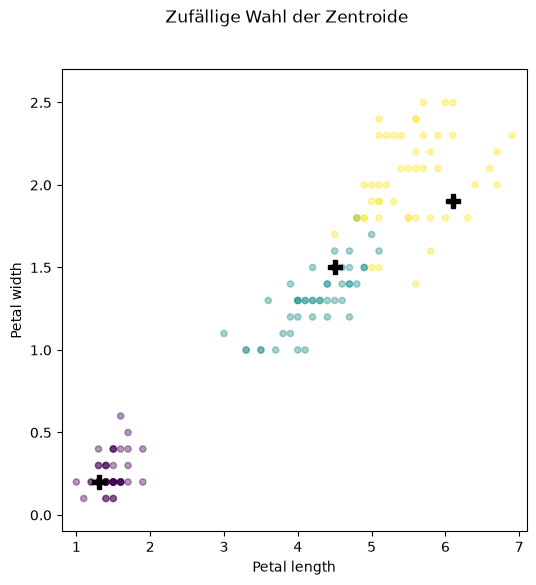

In [4]:
def plotinit(the_data):
    fig, ax = plt.subplots(figsize=(6,6))
    ax.set_xlim(np.min(the_data[:,0])-0.2, np.max(the_data[:,0])+0.2)
    ax.set_ylim(np.min(the_data[:,1])-0.2, np.max(the_data[:,1])+0.2)
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")
    return fig, ax

fig, ax = plotinit(demodata)
ax.scatter(demodata[:,0], demodata[:,1],
           c=classes, vmax=k-1,
           alpha=0.4, s=20)
ax.plot(cs[:,0], cs[:,1],
        'P', c='black', markersize=10)
fig.suptitle("Zufällige Wahl der Zentroide")
plt.show()

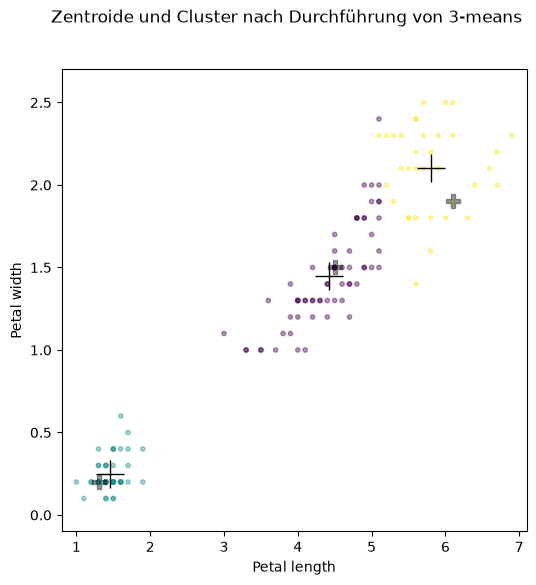

In [5]:
# Wir legen die von k-means geratene Klasse in eine neue Spalte ab:
point_classification = np.full(len(demodata), -1.0)

# Wir merken uns die Geschichte der Zentroide zum Plotten:
cs_history = np.full((len(demodata),k,len(demodata[0])), -1.0)

# Punkt für Punkt wird klassifiziert:
for i, point in enumerate(demodata):
    # Nächstes Zentroid bestimmen:
    distances = [np.linalg.norm(centroid - point) 
                 for centroid in cs]
    pointclass = np.argmin(distances)
    point_classification[i] = pointclass
    # Im ersten Durchlauf werden wir sofort,
    # nicht erst nach dem Durchlauf, das
    # Zentroid neu berechnen:
    cs_history[i] = cs
    cs[pointclass,:] = np.mean(demodata[point_classification == pointclass],
                              axis=0)

# Ergebnisse betrachten:
fig, ax = plotinit(demodata)
ax.scatter(demodata[:,0], demodata[:,1],
           c=point_classification, vmax=k-1,
           alpha=0.4, s=10)
ax.plot(initial_cs[:,0], initial_cs[:,1],
        'P', c='black', markersize=10, alpha=0.4)
ax.plot(cs[:,0], cs[:,1],
        '+', c='black', markersize=20)
fig.suptitle("Zentroide und Cluster nach Durchführung von 3-means")
plt.show()

In [6]:
# Klassenbezeichnungen sind permutiert,
# Zur besseren Visualisierung 'reparieren' wir das,
# dann passen die Farben mit den ursprünglichen Klassen zusammen:
point_classification[point_classification == 0] = 3
point_classification[point_classification == 1] = 0
point_classification[point_classification == 3] = 1

Wie der Algorithmus iterativ die Punkte clustert, kann man sich auch in Ruhe anschauen:

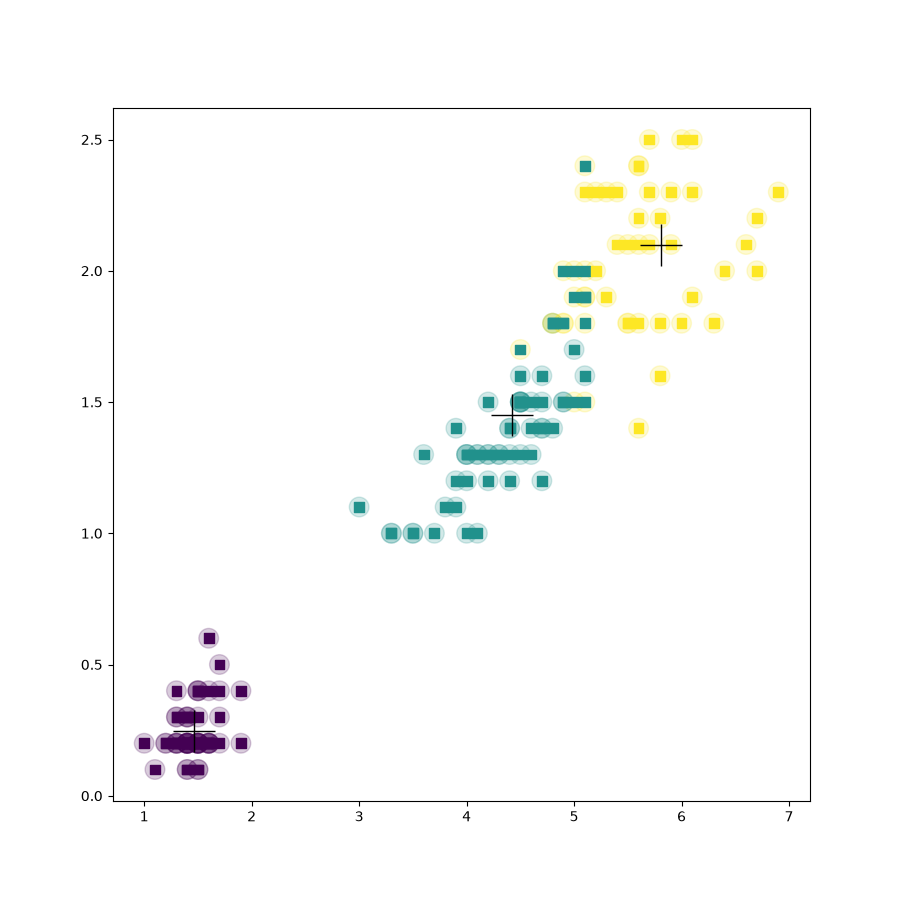

In [7]:
import matplotlib.animation as animation
from IPython import display as ipydisplay
import io, base64

fig, ax = plotinit(demodata)
fig.set_size_inches(9, 9)

def init():
    ax.scatter(demodata[:,0], demodata[:,1],
           c=classes, vmax=k-1, alpha=0.2, s=200)
    
def update(i):
    ax.clear()
    init()
    ax.scatter(demodata[:i+1,0], demodata[:i+1,1],
               vmax=k-1,
               c=point_classification[:i+1],
               marker='s', s=50)
    ax.plot(cs_history[i,:,0], cs_history[i,:,1],
        '+', c='black', markersize=30)

ani = animation.FuncAnimation(fig, update,
                              frames=len(demodata), interval=100,
                              init_func=init)
video = ani.to_html5_video()
# Zusätzlich das letzte Bild als PNG ausgeben: der Web-Export zeigt das Video,
# der PDF-Export (der kein HTML kann) verwendet das Standbild.
png = io.BytesIO()
fig.savefig(png, format='png')
ipydisplay.display({'text/html': video,
                    'image/png': base64.b64encode(png.getvalue()).decode('ascii')},
                   raw=True)
plt.close()

<!-- [kmeans-in-action.mp4](kmeans-in-action.mp4) -->


Man sieht hier, dass wir das Verfahren erneut durchführen können, mit den neuen Zentroiden als Startzentroide, und dabei ein besseres Clustering bekommen. Wenn sich bei wiederholter Durchführung die Cluster (also auch die Zentroide) nicht mehr ändern, spricht man von *Konvergenz*.
Bessere Cluster bekommt man natürlich, wenn man den vollen Datensatz verwendet (also nicht nur 2 Spalten). Wir wollen nun eine Methode implementieren, die einen k-Means-Durchlauf auf einem beliebigen Datensatz durchführt mit vorgegebenen Initialzentroiden. Dabei können wir gleich die vorherige Implementierung durch eine vektorisierte ersetzen:

## Vektorisierte k-Means-Implementierung

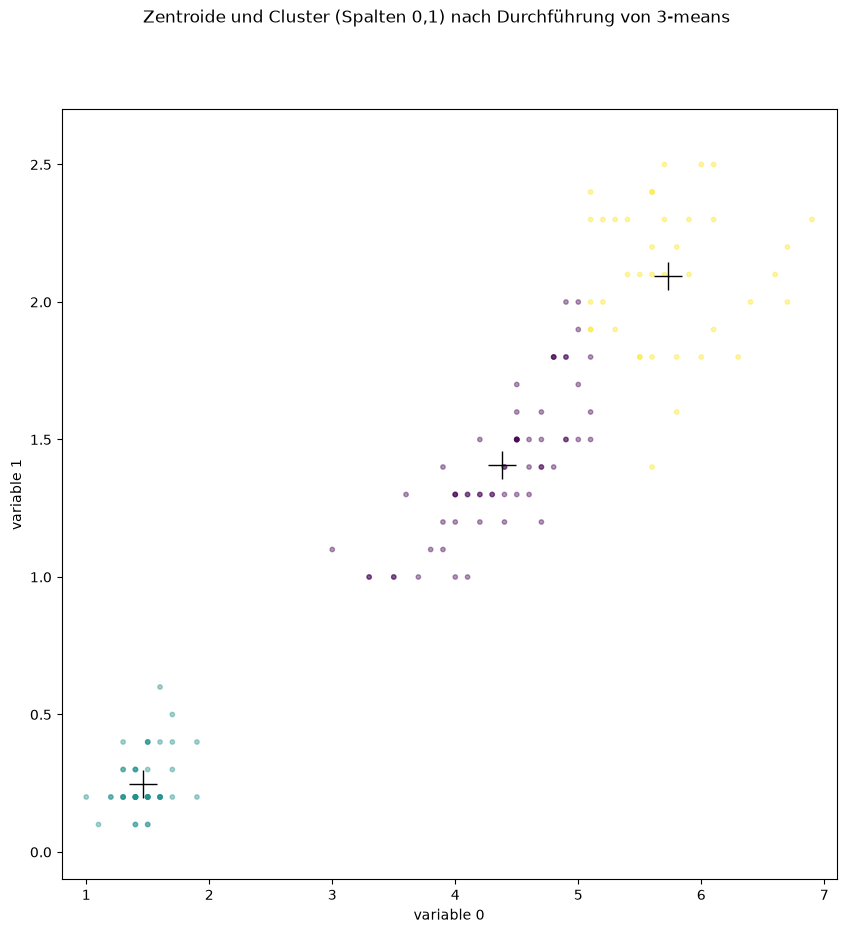

In [8]:
def kmeans(data, k, centroids):
    alldistances = np.array([np.linalg.norm(data - centroid, axis=1)
                             for centroid in centroids])
    assert alldistances.shape == (k, len(data))
    point_classification = np.argmin(alldistances, axis=0)
    new_centroids = np.array([np.mean(data[point_classification == pointclass],
                                      axis=0)
                              for pointclass in np.arange(k)])
    return point_classification, new_centroids

point_classification, new_centroids = kmeans(demodata, 3, cs_history[-1])

# Ergebnisse betrachten:
def plotinit(data, col1=0, col2=1):
    fig, ax = plt.subplots(figsize=(10,10))
    ax.set_xlim(np.min(data[:,col1])-0.2, np.max(data[:,col1])+0.2)
    ax.set_ylim(np.min(data[:,col2])-0.2, np.max(data[:,col2])+0.2)
    ax.set_xlabel("variable %s" % col1)
    ax.set_ylabel("variable %s" % col2)
    return fig, ax

def plot_results(data, k, centroids, classes, col1=0, col2=1):
    fig, ax = plotinit(data, col1=col1, col2=col2)
    ax.scatter(data[:,col1], data[:,col2],
               c=classes, vmax=k-1,
               alpha=0.4, s=10)
    ax.plot(centroids[:,col1], centroids[:,col2],
            '+', c='black', markersize=20)
    fig.suptitle("Zentroide und Cluster (Spalten %s,%s) nach Durchführung von %s-means" % (col1, col2, k))
    plt.show()
    
plot_results(demodata, 3, new_centroids, point_classification, col1=0, col2=1)

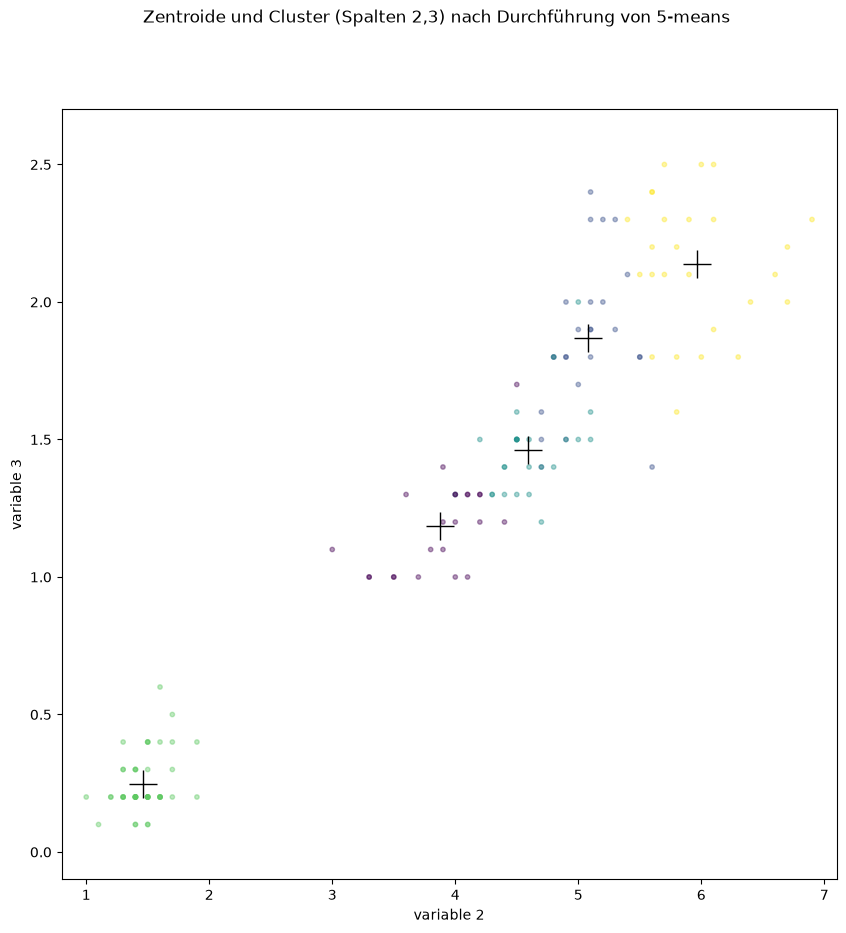

In [9]:
# Weil es jetzt so einfach geht:
k = 5
data = x # sepal length, sepal width, petal length, petal width
random_indices = np.random.choice(len(data), k)
initial_centroids = data[random_indices]
point_classification, new_centroids = kmeans(data, k, initial_centroids)
plot_results(data, k, new_centroids, point_classification, col1=2, col2=3)

## Konvergierende k-Means-Implementierung

iteration step  1
iteration step  2
iteration step  3
iteration step  4
iteration step  5
iteration step  6


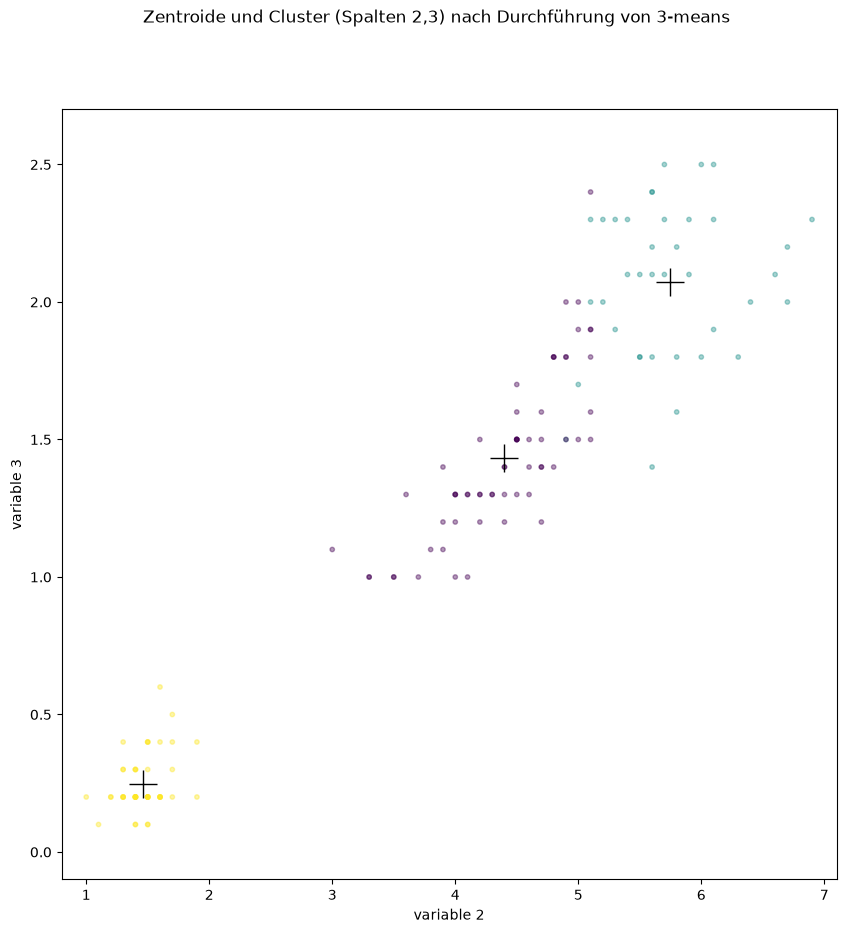

In [10]:
np.random.seed(2222)

# 3-means bis zur Konvergenz:
def convergent_kmeans(data, k, breakloop=100, noisy=True):
    random_indices = np.random.choice(len(data), k)
    new_centroids = data[random_indices]
    old_centroids = np.full(new_centroids.shape, 0) # will be overwritten anyway
    point_classification = None
    i = 0
    while(not np.allclose(old_centroids, new_centroids, rtol=0.0001) and i < breakloop):
        i += 1
        if(noisy):
            print("iteration step ", i)
        old_centroids = new_centroids
        point_classification, new_centroids = kmeans(data, k, old_centroids)
        # if any of the new centroids is NaN, need to replace it by the old one to continue
        # this can happen if centroid is so bad, the empty cluster forms (=> no mean)
        nan_centroids = np.isnan(new_centroids).any(axis=1)
        new_centroids[nan_centroids] = old_centroids[nan_centroids]
    return point_classification, new_centroids

point_classification, new_centroids = convergent_kmeans(data, 3)
plot_results(data, 3, new_centroids, point_classification, col1=2, col2=3)

## Welches k ist das richtige?

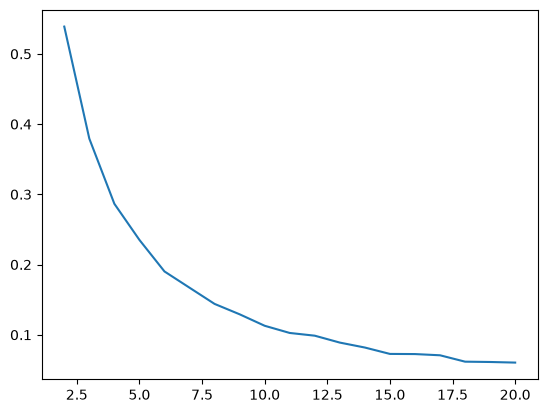

In [11]:
np.random.seed(11111)
max_k_to_try = 20
assert max_k_to_try <= len(data)

import warnings

elbow_values = []
with warnings.catch_warnings():        # nur für diese Schleife: "Mean of empty slice" unterdrücken
    warnings.simplefilter("ignore")
    for k in range(2, max_k_to_try+1):
        #print("looking at k =", k)
        point_classification, centroids = convergent_kmeans(data, k, noisy=False)
        # Berechne für jeden Cluster die innere Varianz:
        total_inner_variance = np.nansum([np.var(data[point_classification == pointclass])
                                          for pointclass in range(k)])
        group_variance = np.var(centroids)
        elbow_values.append(group_variance / total_inner_variance)
    
fig, ax = plt.subplots()
ax.plot(np.arange(2, max_k_to_try+1), elbow_values)
plt.show()

## Robustes k-Means und Elbow plot

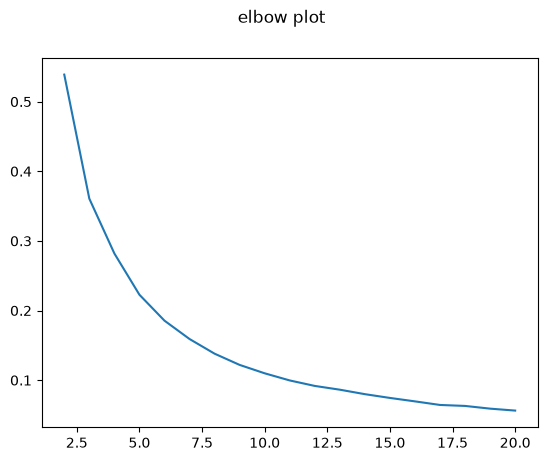

In [12]:
def robust_kmeans(data, k, howmany=20):
    score = 100000000
    for i in range(howmany):
        point_classification, centroids = convergent_kmeans(data, k, noisy=False)
        total_inner_variance = np.nansum([np.var(data[point_classification == pointclass])
                                          for pointclass in range(k)])
        group_variance = np.var(centroids)
        new_score = group_variance / total_inner_variance
        if(new_score < score):
            final_classification, final_centroids = point_classification, centroids
            score = new_score
    return final_classification, final_centroids, score

with warnings.catch_warnings():        # wie oben: leere Cluster erzeugen "Mean of empty slice"
    warnings.simplefilter("ignore")
    elbow_values = [robust_kmeans(data, k)[2] for k in range(2, max_k_to_try+1)]
fig, ax = plt.subplots()
fig.suptitle("elbow plot")
ax.plot(np.arange(2, max_k_to_try+1), elbow_values)
plt.show()


## Beispiel mit anderen Daten

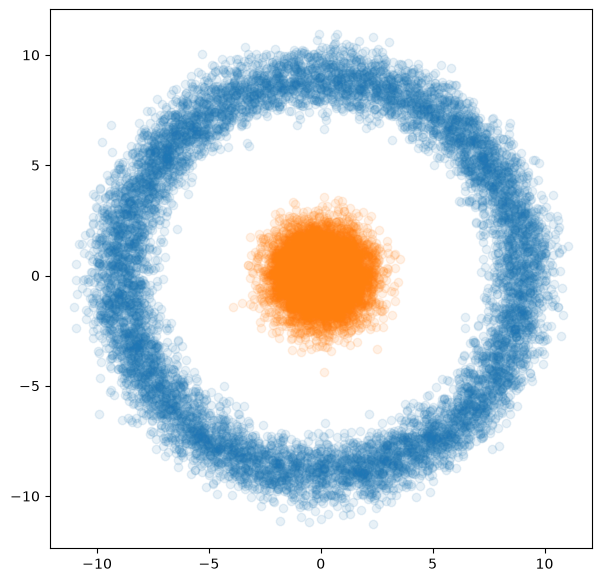

In [13]:
import scipy.stats as st

def ringe(n, radius=(8, 9)):
    rs = st.multivariate_normal(mean=radius[0]+np.ptp(radius),
                                cov=np.ptp(radius)/2
                               ).rvs(size=n)
    phis = st.uniform.rvs(size=n) * 2 * np.pi
    x, y = np.cos(phis), np.sin(phis)
    return (rs * np.stack([x, y])).T

n = 10000
sample = ringe(n)
secondsample = st.multivariate_normal.rvs(mean=[0,0], cov=np.eye(2), size=n)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=1000/n)
ax.scatter(secondsample[:,0], secondsample[:,1], alpha=1000/n)
plt.show()

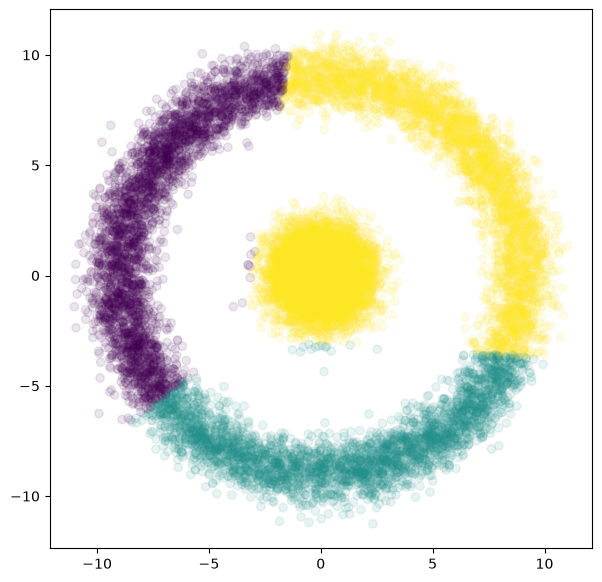

In [14]:
merged_sample = np.concatenate([sample, secondsample])
final_classification, final_centroids, score = robust_kmeans(merged_sample, 3, howmany=10)
#final_classification, final_centroids = convergent_kmeans(merged_sample, 3, breakloop=100, noisy=False)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(merged_sample[:,0], merged_sample[:,1], alpha=0.1, c=final_classification)
plt.show()

## kmeans++

Um dem Problem schlechter initialer Zentroide entgegen zu wirken, kann man den **kmeans++**-Algorithmus verwenden:
1. Wähle ein erstes Zentroid gleichverteilt unter allen Datenpunkten
1. Für jeden Punkt $x$, berechne $D(x)$, den Abstand zum nächsten Zentroid
1. Wähle ein nächstes Zentroid aus, mit einer gewichteten Verteilung, die jedes $x$ mit Gewicht proportional zu $D(x)^2$ auswählt.
1. Wiederhole Schritte 2-3 bis $k$ Zentroide gefunden sind.
1. Gewöhnliches k-Means bis zur Konvergenz

In [15]:
def kmeanspp(data, k):
    centroid_indices = [np.random.choice(len(data))] # uniform
    while(len(centroid_indices) < k):
        distances = np.array([np.linalg.norm(data-centroid, axis=1)
                              for centroid in data[centroid_indices]])
        smallest_distances = np.min(distances, axis=0)
        weights = np.power(smallest_distances, 2)
        # must normalize weights to sum up to 1:
        weights = weights / np.sum(weights)
        new_centroid_index = np.random.choice(len(data), p=weights)
        if(not new_centroid_index in centroid_indices):
            centroid_indices += [new_centroid_index]
    return data[centroid_indices]

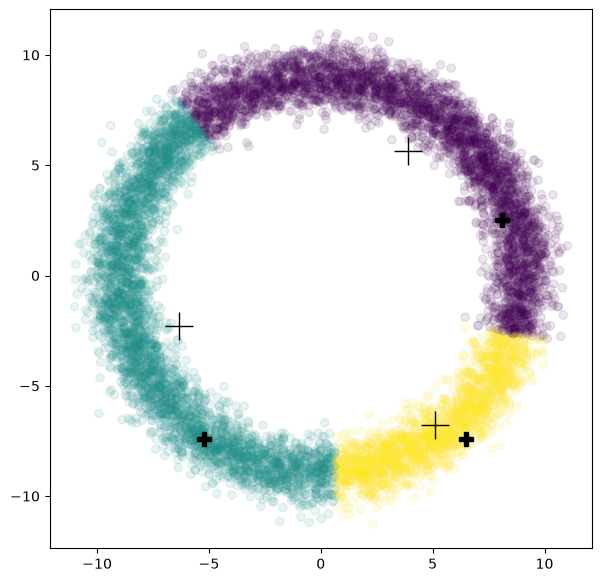

In [16]:
centroids = kmeanspp(sample, 3)
point_classification, new_centroids = kmeans(sample, 3, centroids)
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(sample[:,0], sample[:,1], alpha=0.1, c=point_classification)
ax.plot(new_centroids[:,0], new_centroids[:,1],
            '+', c='black', markersize=20)
ax.plot(centroids[:,0], centroids[:,1],
        'P', c='black', markersize=10)
plt.show()

## Trivia

Was man über k-Means noch wissen sollte:

* Die durchschnittliche Laufzeitkomplexität ist in $O(k*n*T)$ mit $n$ der Samplegröße und $T$ die Anzahl an Iterationen.
* Die Worst-Case-Komplexität ist in $O(n^{(k+2/d)})$ wobei $d$ die Anzahl Variablen (die Dimension) ist. [Arthur, Vassilvitskii: ‘How slow is the k-means method?’, 2006](https://theory.stanford.edu/~sergei/papers/kMeans-socg.pdf)
* Was passiert theoretisch?
  Die sogenannte **Trägheit** (inertia), das ist die Summe der *quadrierten* Abstände aller Punkte zu ihren nächsten Zentroiden, $J(c_1,\dots,c_k) = \sum_i \min_j \lVert x_i - c_j \rVert^2$, wird minimiert. Das zeigt auch das größte Problem auf: wenn die Cluster nicht konvex und homogen sind, ist das eine weniger sinnvolle Optimierungsgröße. Hier greift der Fluch der Dimensionalität (curse of dimensionality): in hochdimensionalen Räumen verhalten sich Abstände unintuitiv, z.B. sind in einer Kugel gleichverteilte Punkte mehr nahe am Rand als nahe der Mitte. Wieder ein Grund mehr, um Hauptachsentransformation zu lernen.
* Variante **bisecting k-means**:
  Zunächst 2-means, dann wird iterativ einer der größten Cluster aufgeteilt mit 2-means usw. bis insgesamt k Cluster da sind.
* Variante **mini-batch k-means**:
  Ein Kompromiss aus unserer ersten Variante (mit der Animation) und der letzten Variante. Hat große Vorteile bei online-Datenverarbeitung (streaming) und generell großen Datenmengen.
* Die Voraussetzung, damit k-means-Verfahren erfolgreich sein können, sind Daten die in Cluster von etwa Ellipsoider Form mit ähnlicher Varianz fallen. [Beispiele, wo es schief gehen kann, sind in der scikit-learn-Dokumentation geplottet](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html#sphx-glr-auto-examples-cluster-plot-kmeans-assumptions-py).
* Das **Elbow Kriterium** ist nicht sinnvoll. Details und Alternativen werden seit Jahren in der Literatur diskutiert {cite}`Schubert2023`.

## k-Means in scikit-learn

Man muss natürlich das Rad nicht neu erfinden, `scikit-learn` bringt k-Means-Implementierungen mit:

In [17]:
from sklearn.cluster import KMeans
# Ist natürlich viel schneller, weil mit C parallelisiert:
kmeans_result = KMeans(n_clusters=3).fit(iris.data)
print(kmeans_result.cluster_centers_)
print(kmeans_result.labels_)
print(iris.target)
from sklearn import metrics
print("NMI = I(P;C) / mean(H(P), H(C)) zwischen Vorhersage P und Klasse C:",
      metrics.normalized_mutual_info_score(iris.target, kmeans_result.labels_))

[[6.85384615 3.07692308 5.71538462 2.05384615]
 [5.006      3.428      1.462      0.246     ]
 [5.88360656 2.74098361 4.38852459 1.43442623]]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
NMI = I(P;C) / mean(H(P), H(C)) zwischen Vorhersage P und Klasse C: 0.7419116631817836


In [18]:
# Das gibt's auch noch:
from sklearn.cluster import MiniBatchKMeans
#from sklearn.cluster import BisectingKMeans # in sklearn v.1.1

## Wo k-Means an seine Grenzen kommt

Der Zuweisungsschritt ordnet jeden Punkt dem nächstgelegenen Zentroid zu. Das zerlegt die ganze
Ebene (allgemein: den ganzen Merkmalsraum) in $k$ Gebiete, die **Voronoi-Zellen** der Zentroide:
Die Grenze zwischen zwei Zellen ist die Mittelsenkrechte auf der Verbindungsstrecke der beiden
Zentroide, also eine Gerade (in höheren Dimensionen eine Hyperebene). Jede Zelle ist ein Schnitt
von Halbebenen und damit **konvex**. Was k-Means findet, ist also immer eine Zerlegung in konvexe
Stücke mit geraden Grenzen — egal, wie die Daten aussehen.

Daraus folgen die typischen Schwächen, an denen man k-Means erkennt:

* **Nichtkonvexe Cluster.** Zwei ineinander liegende Ringe, zwei Halbmonde, zwei Spiralen: Jede
  Gerade schneidet beide, also kann keine Wahl der Zentroide sie trennen. Das haben wir oben bei den
  Ringen gesehen; das Kapitel [Kernel-Methoden](kernel-methoden.ipynb) zeigt den Ausweg, die Daten
  erst so abzubilden, dass die Cluster konvex werden.
* **Sehr unterschiedliche Clustergrößen.** Ein großer Cluster zieht Zentroide an sich und wird
  zerteilt, während kleine Cluster zusammengelegt werden — die Trägheit wird durch Punkte gezählt,
  nicht durch Cluster.
* **Sehr unterschiedliche Ausdehnung (Varianz).** Die Grenze liegt in der Mitte zwischen den
  Zentroiden, nicht dort, wo der breite Cluster aufhört: Der enge Cluster stiehlt dem breiten die
  Randpunkte.
* **Ausreißer.** Ein einzelner weit entfernter Punkt verschiebt ein Zentroid (das Mittel ist nicht
  robust) oder bekommt bei ungünstiger Initialisierung sogar ein eigenes.
* **Merkmale auf verschiedenen Skalen.** Die euklidische Distanz addiert Quadrate; ein Merkmal in
  Metern und eines in Millimetern gewichtet das zweite tausendfach stärker. Vorher skalieren, siehe
  [Dimensionsreduktion](dimensionsreduktion.ipynb).
* **Überlappende Cluster.** Wo sich Verteilungen durchdringen, gibt es keine sinnvolle harte
  Grenze; ein gemischtes Gaußsches Modell mit weichen Zuordnungen
  ([Expectation-Maximization](expectation-maximization.ipynb)) passt dann besser.

Dazu kommt, was wir schon kennen: $k$ muss vorher gewählt werden, und das Ergebnis hängt von der
Initialisierung ab. Die folgenden drei Blobs — einer groß und breit, zwei klein und eng — zeigen
das Größenproblem in einem Bild:


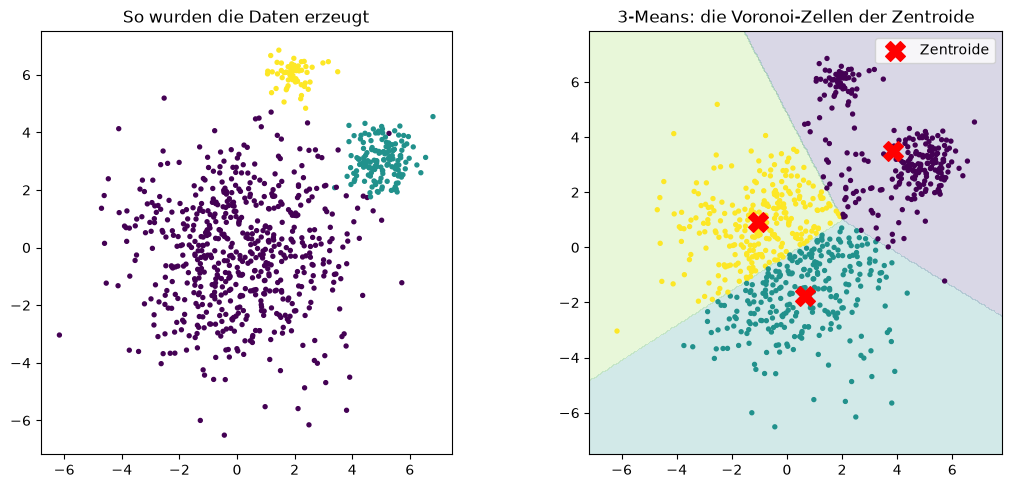

In [19]:
from sklearn.datasets import make_blobs

# drei Blobs: verschieden groß und verschieden breit
X, wahre_klasse = make_blobs(n_samples=[600, 150, 60],
                             centers=[[0, 0], [5, 3], [2, 6]],
                             cluster_std=[2.0, 0.6, 0.4],
                             random_state=7)
km = KMeans(n_clusters=3, n_init=10, random_state=7).fit(X)

# Voronoi-Zellen: jeder Punkt der Ebene bekommt die Farbe seines nächsten Zentroids
xs, ys = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
zellen = km.predict(np.c_[xs.ravel(), ys.ravel()]).reshape(xs.shape)

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
axs[0].scatter(X[:, 0], X[:, 1], c=wahre_klasse, s=8, cmap="viridis")
axs[0].set_title("So wurden die Daten erzeugt")
axs[1].contourf(xs, ys, zellen, levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.2, cmap="viridis")
axs[1].scatter(X[:, 0], X[:, 1], c=km.labels_, s=8, cmap="viridis")
axs[1].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               marker="X", s=200, c="red", label="Zentroide")
axs[1].set_title("3-Means: die Voronoi-Zellen der Zentroide")
axs[1].legend()
for ax in axs:
    ax.set_aspect("equal")
plt.show()


Die Grenzen sind Geraden, die Zellen konvex — und k-Means investiert zwei seiner drei Zentroide in
den großen Cluster und legt die beiden kleinen zu einem zusammen. Das ist kein Fehler des
Verfahrens, sondern genau die Zerlegung mit der kleinsten Trägheit: $600$ Punkte, die halbiert
werden, sparen mehr quadrierte Abstände ein als $210$ Punkte, die getrennt werden. Wer solche Daten
hat, braucht ein Verfahren, das die Form und Größe der Cluster mitmodelliert: ein gemischtes
Gaußsches Modell mit eigener Kovarianzmatrix und eigenem Gewicht je Komponente hätte hier keine Mühe.
